# EDA 01 — Pacientes y lista de espera

La **foto congelada**: quién espera, desde cuándo, por qué especialidad y con qué prioridad inicial.

Dataset sintético HLF · 500 pacientes · fecha de referencia 2026-10-13. Esquema en `docs/datos.md`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from carga import cargar, base_paciente, FECHA_REFERENCIA, ORDEN_PRIORIDAD, RANGOS_NORMALES

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
COLOR_PRIO = {"alta": "#c0392b", "media": "#e67e22", "baja": "#2e86c1"}

d = cargar()
pac = base_paciente(d)
lista, eventos, mediciones, agenda, citas = d["lista"], d["eventos"], d["mediciones"], d["agenda"], d["citas"]

## 1. Calidad e integridad

In [2]:
resumen = pd.DataFrame({
    nombre: {"filas": len(df), "columnas": df.shape[1], "nulos": int(df.isna().sum().sum()),
             "duplicados": int(df.duplicated().sum())}
    for nombre, df in d.items()
}).T
resumen

,filas,columnas,nulos,duplicados
pacientes,500,9,485,0
lista,500,11,0,0
eventos,786,7,0,0
mediciones,2487,6,0,0
agenda,2188,8,0,0
citas,257,7,105,0


In [3]:
# Nulos por columna (solo las que tienen)
pd.concat({n: df.isna().sum()[lambda s: s > 0] for n, df in d.items()}).rename("nulos").to_frame()

,,nulos
pacientes,fecha_defuncion,485
citas,minutos_atencion_real,105


In [4]:
checks = {
    "id_paciente único en pacientes": pac["id_paciente"].is_unique,
    "una solicitud por paciente": lista["id_paciente"].is_unique and len(lista) == len(d["pacientes"]),
    "fallecido ⇔ estado = fallecido": ((pac["fallecido"]) == (pac["estado"] == "fallecido")).all(),
    "fallecido ⇔ fecha_defuncion": ((pac["fallecido"]) == pac["fecha_defuncion"].notna()).all(),
    "defunción posterior al ingreso": (pac.dropna(subset=["fecha_defuncion"]).eval("fecha_defuncion >= fecha_ingreso_lista")).all(),
}
pd.Series(checks, name="ok").to_frame()

,ok
id_paciente único en pacientes,True
una solicitud por paciente,True
fallecido ⇔ estado = fallecido,True
fallecido ⇔ fecha_defuncion,True
defunción posterior al ingreso,True


## 2. Demografía

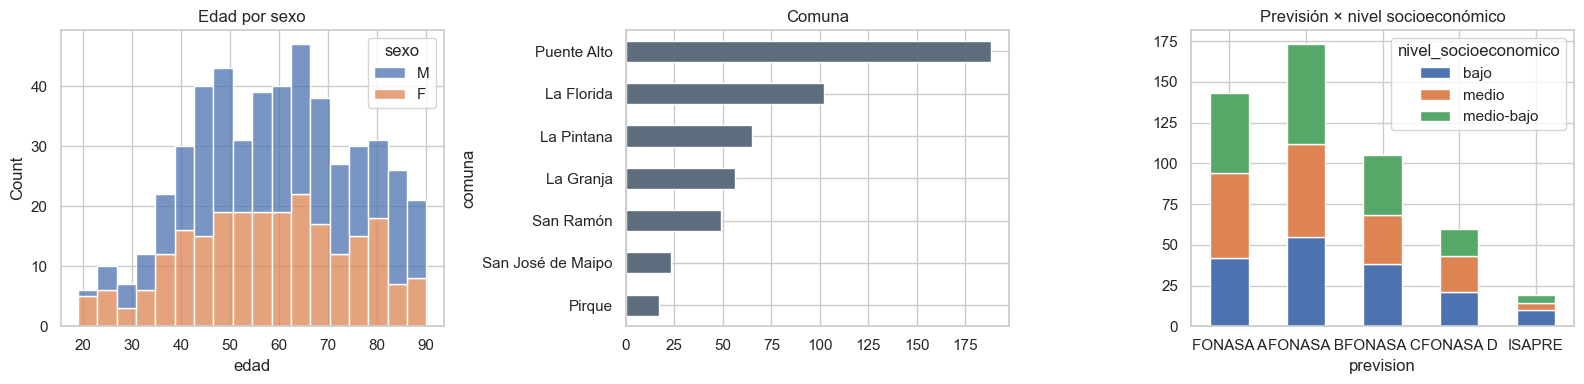

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(pac, x="edad", hue="sexo", multiple="stack", bins=18, ax=ax[0]).set_title("Edad por sexo")
pac["comuna"].value_counts().plot.barh(ax=ax[1], color="#5d6d7e").set_title("Comuna")
ax[1].invert_yaxis()
pd.crosstab(pac["prevision"], pac["nivel_socioeconomico"]).plot.bar(stacked=True, ax=ax[2], rot=0).set_title("Previsión × nivel socioeconómico")
plt.tight_layout()

In [6]:
pac[["edad"]].describe().T.join(pac["sexo"].value_counts(normalize=True).rename(lambda s: f"% {s}").to_frame().T.reset_index(drop=True).set_index(pd.Index(["edad"])))

,count,mean,std,min,25%,50%,75%,max,% M,% F
edad,500.0,59.076,16.825469,19.0,46.0,59.5,72.0,90.0,0.524,0.476


## 3. Composición de la lista

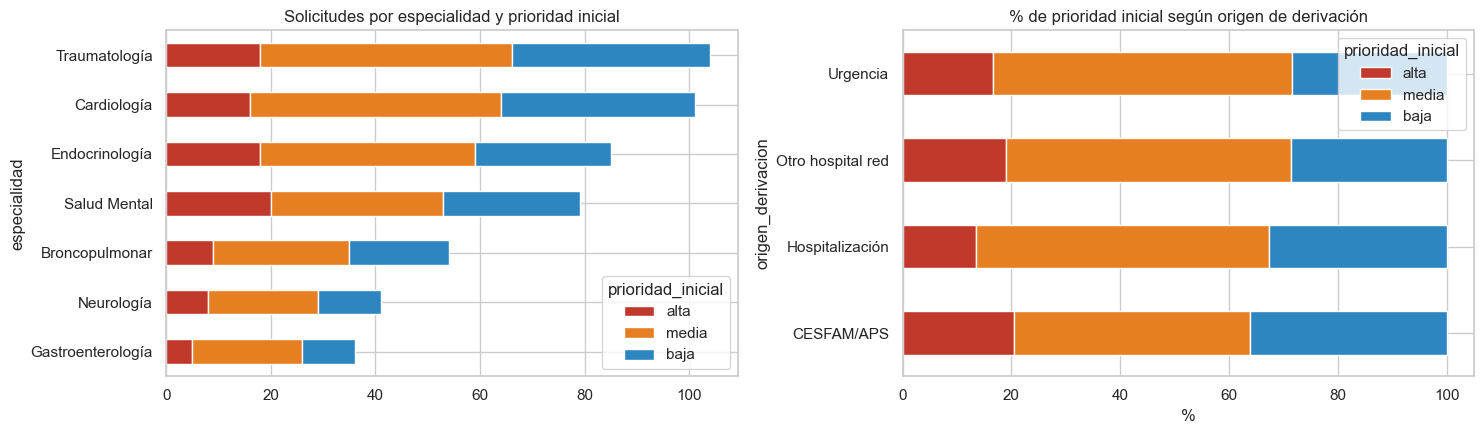

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ct = pd.crosstab(lista["especialidad"], lista["prioridad_inicial"])
ct.loc[ct.sum(1).sort_values().index].plot.barh(stacked=True, ax=ax[0], color=[COLOR_PRIO[c] for c in ct.columns]).set_title("Solicitudes por especialidad y prioridad inicial")
pd.crosstab(lista["origen_derivacion"], lista["prioridad_inicial"], normalize="index").mul(100).plot.barh(
    stacked=True, ax=ax[1], color=[COLOR_PRIO[c] for c in ORDEN_PRIORIDAD]).set_title("% de prioridad inicial según origen de derivación")
ax[1].set_xlabel("%")
plt.tight_layout()

In [8]:
(lista.groupby(["especialidad", "sub_especialidad", "diagnostico_cie10", "diagnostico_texto"])
      .agg(n=("id_solicitud", "size"),
           pct_alta=("prioridad_inicial", lambda s: round((s == "alta").mean() * 100, 1)))
      .sort_values("n", ascending=False))

n  \
especialidad      sub_especialidad       diagnostico_cie10 diagnostico_texto              
Salud Mental      Psiquiatría adulto     F32               Episodio depresivo        42   
Traumatología     Columna                M54               Lumbago                   39   
Cardiología       Cardiología adulto     I20               Angina de pecho           38   
Salud Mental      Psicología             F41               Trastorno de ansiedad     37   
Cardiología       Cardiología adulto     I10               Hipertensión esencial     35   
Traumatología     Hombro                 M75               Lesión del hombro         34   
                  Rodilla                M17               Artrosis de rodilla       31   
Endocrinología    Diabetes               E11               Diabetes mellitus tipo 2  29   
Broncopulmonar    Asma                   J45               Asma                      28   
Cardiología       Insuficiencia cardíaca I50               Insuficiencia cardíaca    28   
Endocrinología    Tiroides               E03               Hipotiroidismo            28   
                  Diabetes               E66               Obesidad                  28   
Broncopulmonar    EPOC                   J44               EPOC                      26   
Neurología        Cefaleas               G43               Migraña                   22   
Gastroenterología Digestivo alto         K21               Enfermedad por reflujo    19   
Neurología        Epilepsia              G40               Epilepsia                 19   
Gastroenterología Hígado                 K70               Enfermedad hepática       17   

                                                                                     pct_alta  
especialidad      sub_especialidad       diagnostico_cie10 diagnostico_texto                   
Salud Mental      Psiquiatría adulto     F32               Episodio depresivo            28.6  
Traumatología     Columna                M54               Lumbago                       25.6  
Cardiología       Cardiología adulto     I20               Angina de pecho                7.9  
Salud Mental      Psicología             F41               Trastorno de ansiedad         21.6  
Cardiología       Cardiología adulto     I10               Hipertensión esencial         20.0  
Traumatología     Hombro                 M75               Lesión del hombro             14.7  
                  Rodilla                M17               Artrosis de rodilla            9.7  
Endocrinología    Diabetes               E11               Diabetes mellitus tipo 2      17.2  
Broncopulmonar    Asma                   J45               Asma                          14.3  
Cardiología       Insuficiencia cardíaca I50               Insuficiencia cardíaca        21.4  
Endocrinología    Tiroides               E03               Hipotiroidismo                17.9  
                  Diabetes               E66               Obesidad                      28.6  
Broncopulmonar    EPOC                   J44               EPOC                          19.2  
Neurología        Cefaleas               G43               Migraña                        9.1  
Gastroenterología Digestivo alto         K21               Enfermedad por reflujo        10.5  
Neurología        Epilepsia              G40               Epilepsia                     31.6  
Gastroenterología Hígado                 K70               Enfermedad hepática           17.6

In [9]:
pd.crosstab(lista["estado"], lista["prioridad_inicial"], margins=True)

prioridad_inicial,alta,media,baja,All
estado,,,,
atendido,13,35,28,76
en_espera,76,196,137,409
fallecido,5,7,3,15
All,94,238,168,500


## 4. ¿Qué explica la prioridad inicial?

Si la prioridad inicial dependiera de la gravedad clínica, debería asociarse con el origen (urgencia / hospitalización) y quizá con la edad. Prueba χ² para variables categóricas.

In [10]:
from scipy.stats import chi2_contingency, kruskal

filas = []
for var in ["especialidad", "origen_derivacion", "sexo", "comuna", "prevision", "nivel_socioeconomico"]:
    t = pd.crosstab(pac[var], pac["prioridad_inicial"])
    chi2, p, dof, _ = chi2_contingency(t)
    v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
    filas.append({"variable": var, "chi2": round(chi2, 1), "gl": dof, "p": round(p, 4), "V de Cramér": round(v, 3)})
h, p = kruskal(*[g["edad"] for _, g in pac.groupby("prioridad_inicial", observed=True)])
filas.append({"variable": "edad (Kruskal-Wallis)", "chi2": round(h, 1), "gl": 2, "p": round(p, 4), "V de Cramér": np.nan})
pd.DataFrame(filas).set_index("variable")

,chi2,gl,p,V de Cramér
variable,,,,
especialidad,6.3,12,0.9025,0.079
origen_derivacion,6.1,6,0.4146,0.078
sexo,1.3,2,0.5296,0.050
comuna,14.6,12,0.2642,0.121
prevision,10.3,8,0.2441,0.102
nivel_socioeconomico,0.4,4,0.9829,0.020
edad (Kruskal-Wallis),1.9,2,0.3847,NaN


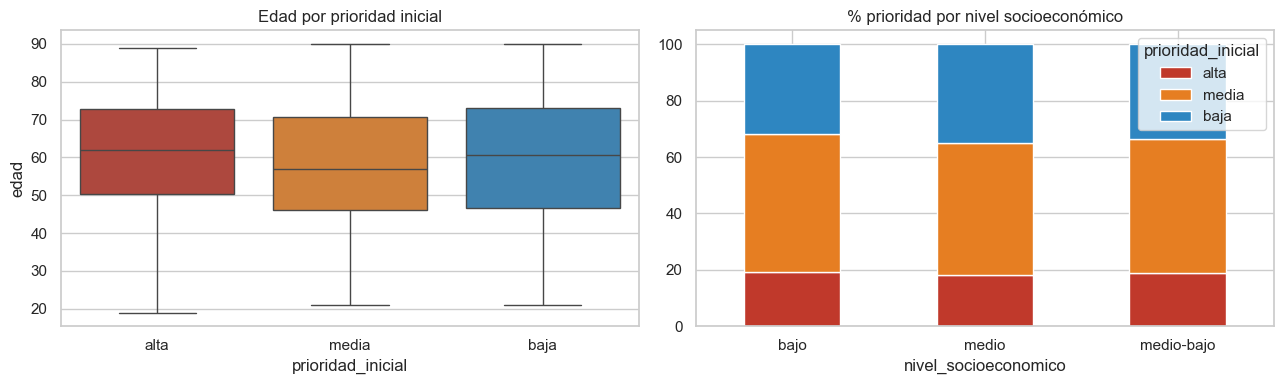

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(pac, x="prioridad_inicial", y="edad", order=ORDEN_PRIORIDAD, palette=COLOR_PRIO, ax=ax[0]).set_title("Edad por prioridad inicial")
pd.crosstab(pac["nivel_socioeconomico"], pac["prioridad_inicial"], normalize="index").mul(100).plot.bar(
    stacked=True, rot=0, ax=ax[1], color=[COLOR_PRIO[c] for c in ORDEN_PRIORIDAD]).set_title("% prioridad por nivel socioeconómico")
plt.tight_layout()

## 5. Tiempo de espera

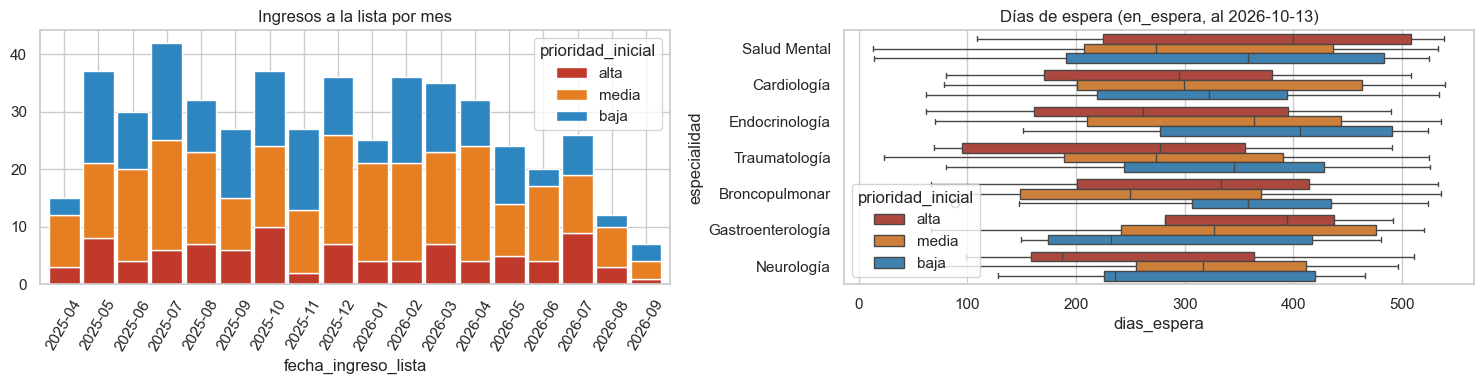

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ingresos = pd.crosstab(lista["fecha_ingreso_lista"].dt.strftime("%Y-%m"), lista["prioridad_inicial"])
ingresos.plot.bar(stacked=True, ax=ax[0], color=[COLOR_PRIO[c] for c in ingresos.columns], width=0.9, rot=60)
ax[0].set_title("Ingresos a la lista por mes")
activos = lista[lista["estado"] == "en_espera"]
sns.boxplot(activos, x="dias_espera", y="especialidad", hue="prioridad_inicial", hue_order=ORDEN_PRIORIDAD, palette=COLOR_PRIO, ax=ax[1])
ax[1].set_title("Días de espera (en_espera, al 2026-10-13)")
plt.tight_layout()

In [13]:
activos.groupby("prioridad_inicial", observed=True)["dias_espera"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
prioridad_inicial,,,,,,,,
alta,76.0,294.0,149.0,20.0,161.0,301.0,412.0,539.0
media,196.0,307.0,143.0,13.0,194.0,293.0,439.0,540.0
baja,137.0,325.0,133.0,14.0,226.0,335.0,443.0,534.0


In [14]:
# Días hasta la atención para los atendidos (primera cita con asistio)
primera_asist = citas[citas["estado_cita"] == "asistio"].groupby("id_paciente")["fecha_cita"].min()
at = lista[lista["estado"] == "atendido"].set_index("id_paciente").join(primera_asist)
at["dias_hasta_atencion"] = (at["fecha_cita"] - at["fecha_ingreso_lista"]).dt.days
at.groupby("prioridad_inicial", observed=True)["dias_hasta_atencion"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
prioridad_inicial,,,,,,,,
alta,13.0,262.0,123.0,74.0,158.0,306.0,380.0,416.0
media,35.0,213.0,114.0,14.0,140.0,210.0,278.0,479.0
baja,28.0,245.0,118.0,11.0,187.0,254.0,330.0,494.0


## 6. Fallecidos en espera

Control de exclusión: deben salir de la lista.

In [15]:
fall = pac[pac["fallecido"]].copy()
fall["dias_ingreso_a_defuncion"] = (fall["fecha_defuncion"] - fall["fecha_ingreso_lista"]).dt.days
fall[["id_paciente", "edad", "especialidad", "diagnostico_cie10", "prioridad_inicial", "origen_derivacion",
      "fecha_ingreso_lista", "fecha_defuncion", "dias_ingreso_a_defuncion"]].sort_values("fecha_defuncion")

,id_paciente,edad,especialidad,diagnostico_cie10,prioridad_inicial,origen_derivacion,fecha_ingreso_lista,fecha_defuncion,dias_ingreso_a_defuncion
75,PAC-HLF-00076,48,Salud Mental,F32,media,Otro hospital red,2025-10-13,2025-11-19,37
316,PAC-HLF-00317,73,Broncopulmonar,J45,media,Otro hospital red,2025-08-17,2025-11-21,96
71,PAC-HLF-00072,59,Gastroenterología,K21,media,CESFAM/APS,2025-12-02,2026-01-13,42
88,PAC-HLF-00089,43,Traumatología,M54,alta,CESFAM/APS,2025-10-22,2026-02-20,121
36,PAC-HLF-00037,62,Cardiología,I50,media,CESFAM/APS,2025-08-17,2026-02-27,194
9,PAC-HLF-00010,46,Traumatología,M75,media,Urgencia,2025-12-15,2026-03-17,92
305,PAC-HLF-00306,68,Salud Mental,F41,media,CESFAM/APS,2025-12-18,2026-03-31,103
25,PAC-HLF-00026,62,Traumatología,M75,media,CESFAM/APS,2026-01-29,2026-04-03,64
487,PAC-HLF-00488,82,Endocrinología,E11,alta,Urgencia,2025-07-18,2026-04-04,260
315,PAC-HLF-00316,66,Salud Mental,F41,alta,Otro hospital red,2025-10-23,2026-06-08,228


In [16]:
pd.DataFrame({
    "fallecidos %": pac.groupby("prioridad_inicial", observed=True)["fallecido"].mean().mul(100).round(1),
    "n": pac.groupby("prioridad_inicial", observed=True).size(),
})

,fallecidos %,n
prioridad_inicial,,
alta,5.3,94
media,2.9,238
baja,1.8,168


## Hallazgos

1. **Datos íntegros.** Sin duplicados; los únicos nulos son esperados (`fecha_defuncion` de los vivos, `minutos_atencion_real` de las citas sin asistencia). Fallecido, estado y fecha de defunción son coherentes.
2. **La prioridad inicial no se explica por ninguna variable disponible.** Ni especialidad, origen de derivación, edad, sexo, comuna, previsión ni nivel socioeconómico se asocian con ella (todas p > 0,2; V de Cramér ≤ 0,12). Incluso los derivados desde urgencia u hospitalización no tienen más prioridad alta. La foto inicial se comporta como ruido respecto de lo observable.
3. **La prioridad no ordena la atención.** Los pacientes en espera con prioridad alta llevan casi lo mismo que los de baja (mediana 301 vs. 335 días). Entre los atendidos, los de prioridad alta esperaron *más* (mediana 306 días) que los de media (210).
4. **Esperas largas.** La mediana de espera de los 409 pacientes activos es de unos 300 días.
5. **Fallecidos:** 15 (3 %), más frecuentes en prioridad alta (5,3 %) que en baja (1,8 %). Uno de ellos fallece 32 días después de ingresar (PAC-HLF-00009).
